In [14]:
# Flipper Length and Body Mass in Palmer Penguins

**Question:** How are flipper length and body mass related, and does that relationship differ by penguin species and sex?


Object `sex` not found.


In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from palmerpenguins import load_penguins

penguins = load_penguins()

display(penguins.head())
print("Rows and columns:", penguins.shape)
print("\nMissing values by column:")
print(penguins.isna().sum())


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


Rows and columns: (344, 8)

Missing values by column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


In [16]:
analysis = penguins.dropna(
    subset=["species", "sex", "flipper_length_mm", "body_mass_g"]
).copy()

print("Rows in original data:", len(penguins))
print("Rows used in this analysis:", len(analysis))
print("\nMeasurements by species and sex:")
display(
    analysis.groupby(["species", "sex"])[
        ["flipper_length_mm", "body_mass_g"]
    ].agg(["count", "mean", "median"]).round(1)
)


Rows in original data: 344
Rows used in this analysis: 333

Measurements by species and sex:


flipper_length_mm               body_mass_g                
                             count   mean median       count    mean  median
species   sex                                                               
Adelie    female                73  187.8  188.0          73  3368.8  3400.0
          male                  73  192.4  193.0          73  4043.5  4000.0
Chinstrap female                34  191.7  192.0          34  3527.2  3550.0
          male                  34  199.9  200.5          34  3939.0  3950.0
Gentoo    female                58  212.7  212.0          58  4679.7  4700.0
          male                  61  221.5  221.0          61  5484.8  5500.0

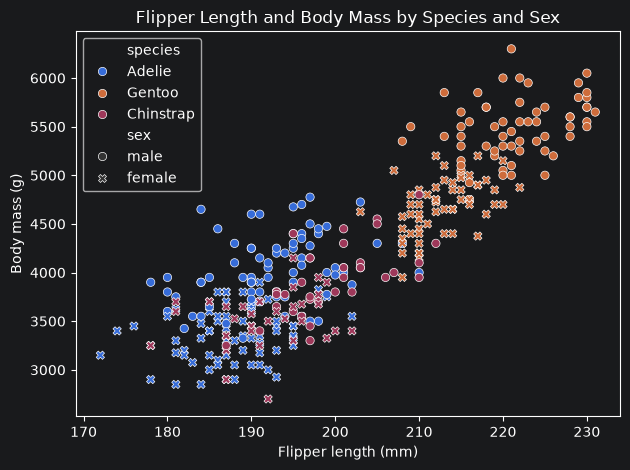

In [17]:
sns.scatterplot(
    data=analysis,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    style="sex"
)

plt.title("Flipper Length and Body Mass by Species and Sex")
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.tight_layout()
plt.show()


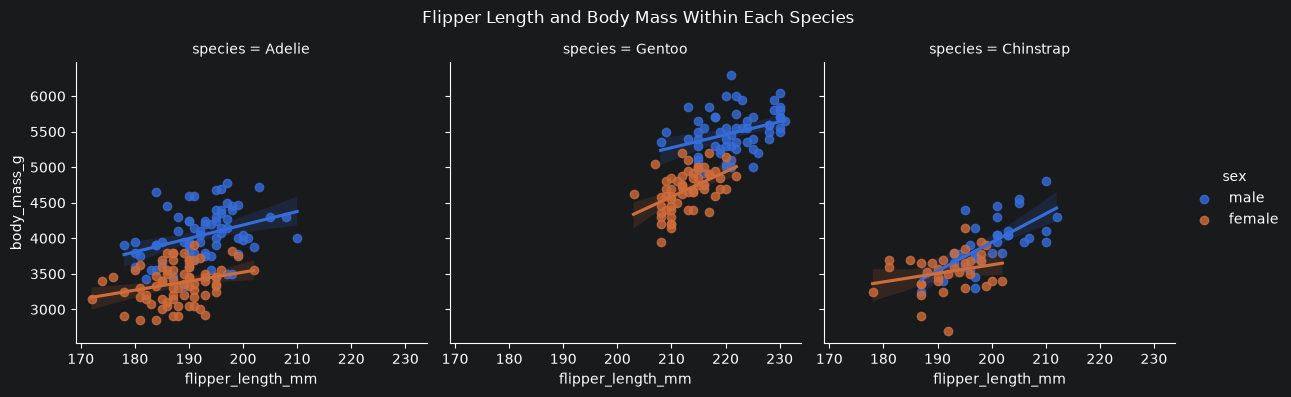

In [18]:
sns.lmplot(
    data=analysis,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="sex",
    col="species",
    height=4,
    aspect=1
)

plt.subplots_adjust(top=0.85)
plt.suptitle("Flipper Length and Body Mass Within Each Species")
plt.show()


In [19]:
analysis.groupby("species")[["flipper_length_mm", "body_mass_g"]].corr().iloc[0::2, -1]


species                     
Adelie     flipper_length_mm    0.464854
Chinstrap  flipper_length_mm    0.641559
Gentoo     flipper_length_mm    0.711305
Name: body_mass_g, dtype: float64

In [20]:
for species, group in analysis.groupby("species"):
    correlation = group["flipper_length_mm"].corr(group["body_mass_g"])
    print(f"{species}: correlation = {correlation:.2f} (n = {len(group)})")


Adelie: correlation = 0.46 (n = 146)
Chinstrap: correlation = 0.64 (n = 68)
Gentoo: correlation = 0.71 (n = 119)


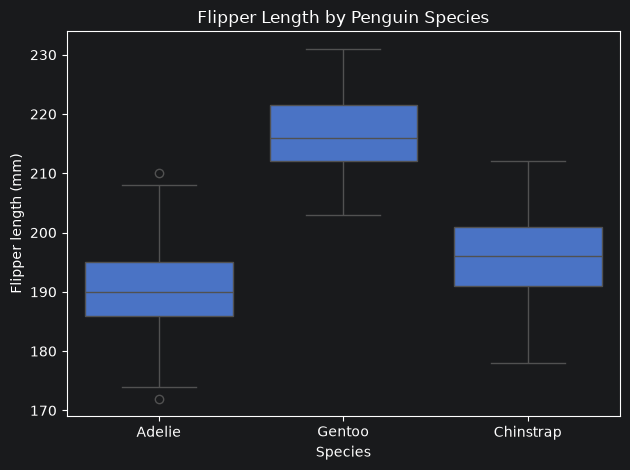

In [21]:
sns.boxplot(data=analysis, x="species", y="flipper_length_mm")
plt.title("Flipper Length by Penguin Species")
plt.xlabel("Species")
plt.ylabel("Flipper length (mm)")
plt.tight_layout()
plt.show()


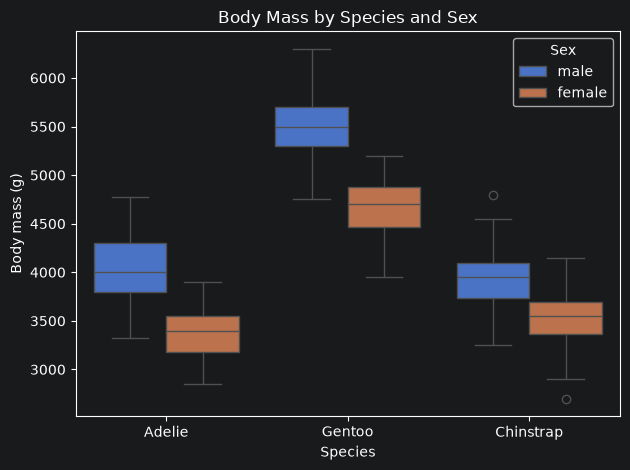

In [22]:
sns.boxplot(data=analysis, x="species", y="body_mass_g", hue="sex")
plt.title("Body Mass by Species and Sex")
plt.xlabel("Species")
plt.ylabel("Body mass (g)")
plt.legend(title="Sex")
plt.tight_layout()
plt.show()


In [23]:
display(
    analysis.groupby(["species", "sex"])[
        ["flipper_length_mm", "body_mass_g"]
    ].median().round(1)
)


flipper_length_mm  body_mass_g
species   sex                                   
Adelie    female              188.0       3400.0
          male                193.0       4000.0
Chinstrap female              192.0       3550.0
          male                200.5       3950.0
Gentoo    female              212.0       4700.0
          male                221.0       5500.0

In [24]:
required = ["species", "sex", "flipper_length_mm", "body_mass_g"]

print("Original rows:", len(penguins))
print("Duplicate full rows:", penguins.duplicated().sum())

print("\nMissing values in the fields used for analysis:")
display(penguins[required].isna().sum().rename("missing"))

incomplete_rows = penguins[required].isna().any(axis=1).sum()
print("Rows missing at least one required field:", incomplete_rows)
print("Rows used in analysis:", len(analysis))
print("Rows excluded:", len(penguins) - len(analysis))


Original rows: 344
Duplicate full rows: 0

Missing values in the fields used for analysis:


species               0
sex                  11
flipper_length_mm     2
body_mass_g           2
Name: missing, dtype: int64

Rows missing at least one required field: 11
Rows used in analysis: 333
Rows excluded: 11


In [25]:
print("penguins columns:", penguins.columns.tolist())
print("penguins shape:", penguins.shape)
display(penguins.head())


penguins columns: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']
penguins shape: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [26]:
required = ["species", "sex", "flipper_length_mm", "body_mass_g"]

print("Original rows:", len(penguins))
print("Duplicate full rows:", penguins.duplicated().sum())

print("\nMissing values in the fields used for analysis:")
display(penguins[required].isna().sum().rename("missing"))

incomplete_rows = penguins[required].isna().any(axis=1).sum()
print("Rows missing at least one required field:", incomplete_rows)
print("Rows used in analysis:", len(analysis))
print("Rows excluded:", len(penguins) - len(analysis))


Original rows: 344
Duplicate full rows: 0

Missing values in the fields used for analysis:


species               0
sex                  11
flipper_length_mm     2
body_mass_g           2
Name: missing, dtype: int64

Rows missing at least one required field: 11
Rows used in analysis: 333
Rows excluded: 11


In [27]:
# Cleaning log

# Checked for duplicate full rows: none found.
# Excluded 11 rows missing at least one field needed for this analysis:  species, sex, flipper length, or body mass.
# Rows before filtering: 344.
# Rows after filtering: 333.
# Kept the original data in `penguins`; the filtered data is stored in `analysis`.


In [28]:
# Findings

# Flipper length and body mass had a positive correlation within each species: Adelie (0.46), Chinstrap (0.64), and Gentoo (0.71). The association was strongest for Gentoo and weakest for Adelie.

# Median flipper length and median body mass were higher for males than females within each species. Gentoo penguins had the highest medians for both measurements among the three species.

# These are patterns in the analyzed data that does not show that longer flippers cause greater body mass.


In [29]:
# Limitations

# The analysis excludes 11 rows with missing values in fields needed for the comparisons, those penguins may differ from the included records.
# Calculated with each species and a combine female and male penguins, the differences between sexes may affect correlations.
# The data shows associations, not cause and effect.
# Results describe this dataset and do not necessarily represent every penguin population.


In [29]:
### Readme
# Palmer Penguins: Flipper Length and Body Mass

# Author: Jasmine Houston

## Project question

# How are flipper length and body mass related among Adelie, Chinstrap, and Gentoo penguins. Also how do the measurements compare by species and sex?

## Dataset

#This analysis uses the Palmer Penguins dataset. The original dataset contains 344 penguins and includes species, sex, flipper length, body mass, and other measurements.

## Data cleaning

# Checked for duplicate full rows: none were found.
# Excluded 11 rows that were missing at least one field needed for this analysis: species, sex, flipper length, or body mass.
# The analysis uses the remaining 333 rows.
# The original data is stored in penguins, the filtered data is stored in `analysis.

## Findings

# Flipper length and body mass had a positive correlation within each species:

# Adelie: 0.46
# Chinstrap: 0.64
# Gentoo: 0.71

# The association was strongest for Gentoo and weakest for Adelie. These correlations describe association, not cause and effect.

# Median flipper length and median body mass were higher for males than females within each species. Gentoo penguins had the highest medians for both measurements among the three species.

## Limitations

# The analysis excludes 11 rows with missing values in fields used for the comparisons.
# The correlations are calculated within each species while combining female and male penguins; sex differences may affect the results.
# The results describe patterns in this dataset and may not represent every penguin population.
# The analysis shows associations and group differences, not cause and effect.

## Charts

# This notebook includes:

# 1. Flipper length versus body mass, colored by species and marked by sex.
# 2. Flipper length distributions by species.
# 3. Body mass distributions by species and sex.

## Data citation and license

# Horst AM, Hill AP, and Gorman KB (2020).  palmerpenguins: Palmer Archipelago (Antarctica) penguin data. DOI: 10.5281/zenodo.3960218.

# The dataset documentation lists the data as available under CC0, subject to the stated Palmer Station LTER and LTER data use policies.

